In [1]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/bergerot/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python311.zip', '/usr/lib/python3.11', '/usr/lib/python3.11/lib-dynload', '', '/usr/local/lib/python3.11/dist-packages', '/usr/lib/python3/dist-packages', '/usr/lib/python3.11/dist-packages']


In [2]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

import pandas as pd
import seaborn as sns

/home/bergerot/Documents/PhD/Code/DistRLdynamics/../CRLDenv/lib/python3.11/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [3]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

In [4]:
from DistBaseExact import distbase

In [5]:
# Define environment
env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

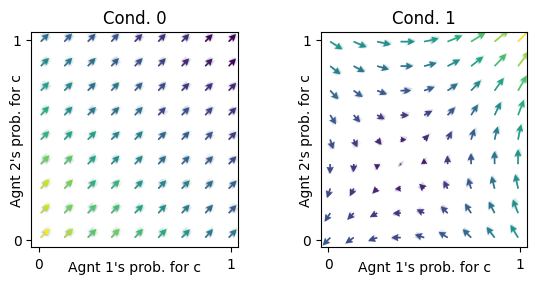

In [6]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

In [7]:
def compute_error(Xs, bin_nrs, sigmas, lr, gamma, path, version):
    for i, nr in enumerate(bin_nrs):
        errors = np.zeros((2, len(sigmas)))
        for j, sigma in enumerate(sigmas):
            print("Bin number "+str(nr)+", sigma="+str(sigma))
            db = distbase(env, nr_reward_bins=nr, 
                          discretization_sigma=sigma, learning_rates=lr, discount_factors=gamma)
            for k, x in enumerate(Xs):
                distRPE = db.TDerror(x)
                detRPE = mae.TDerror(x)
                error_d = np.linalg.norm(detRPE[:,0,:]-distRPE[:,0,:])
                error_p = np.linalg.norm(detRPE[:,1,:]-distRPE[:,1,:])
                errors[0, j] += error_d
                errors[1, j] += error_p
        index = ["degraded", "prosperous"]
        columns = ["sig="+str(sigma) for sigma in sigmas]
        df = pd.DataFrame(errors, index=index, columns=columns)
        df.to_csv(path+"error_df_"+str(nr)+"_bins_"+version+".csv")
    return df

In [8]:
# Initialization
path = "data/exact_method/"
version = "2024-05-06-v1.0"
lr = 0.1
gamma = 0.9
bin_nrs = np.linspace(4, 40, 37).astype(int)
sigmas = [1.]
Xs = []
Pc = np.linspace(0, 1, 101)
Pc[0] = 0.001
Pc[-1] = 0.999
for i, p in enumerate(Pc):
    Xisa = np.zeros((2, 2, 2))
    Xisa[:, :, 0] = p
    Xisa[:, :, 1] = 1-p
    Xs.append(Xisa)

In [9]:
errors = compute_error(Xs, bin_nrs, sigmas, lr, gamma, path, version)

Bin number 4, sigma=1.0
Bin number 5, sigma=1.0
Bin number 6, sigma=1.0
Bin number 7, sigma=1.0
Bin number 8, sigma=1.0
Bin number 9, sigma=1.0
Bin number 10, sigma=1.0
Bin number 11, sigma=1.0
Bin number 12, sigma=1.0
Bin number 13, sigma=1.0
Bin number 14, sigma=1.0
Bin number 15, sigma=1.0
Bin number 16, sigma=1.0
Bin number 17, sigma=1.0
Bin number 18, sigma=1.0
Bin number 19, sigma=1.0
Bin number 20, sigma=1.0
Bin number 21, sigma=1.0
Bin number 22, sigma=1.0
Bin number 23, sigma=1.0
Bin number 24, sigma=1.0
Bin number 25, sigma=1.0
Bin number 26, sigma=1.0
Bin number 27, sigma=1.0
Bin number 28, sigma=1.0
Bin number 29, sigma=1.0
Bin number 30, sigma=1.0
Bin number 31, sigma=1.0
Bin number 32, sigma=1.0
Bin number 33, sigma=1.0
Bin number 34, sigma=1.0
Bin number 35, sigma=1.0
Bin number 36, sigma=1.0
Bin number 37, sigma=1.0
Bin number 38, sigma=1.0
Bin number 39, sigma=1.0
Bin number 40, sigma=1.0


In [13]:
# Retrieve data and put it in array
errors = np.zeros((2, len(bin_nrs)))
for i, nr in enumerate(bin_nrs):
    df = pd.read_csv(path+"error_df_"+str(nr)+"_bins_"+version+".csv")
    npdf = df.to_numpy()
    errors[0, i] = npdf[0][1:]
    errors[1, i] = npdf[1][1:]

/tmp/ipykernel_3528541/3484877825.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  errors[0, i] = npdf[0][1:]
/tmp/ipykernel_3528541/3484877825.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  errors[1, i] = npdf[1][1:]
/tmp/ipykernel_3528541/3484877825.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  errors[0, i] = npdf[0][1:]
/tmp/ipykernel_3528541/3484877825.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and wi

Text(0.5, 1.0, 'Prosperous environment')

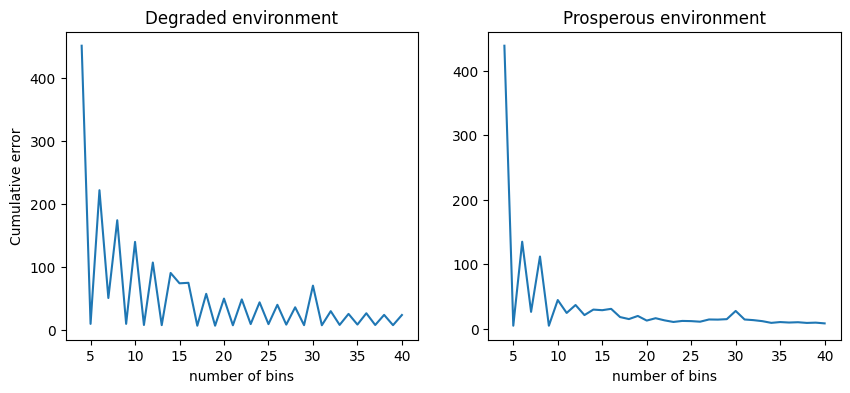

In [14]:
# Plot errors as curves

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    ax.plot(bin_nrs, errors[i, :])
    ax.set_xlabel("number of bins")
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")
# ax2.legend()

Text(0.5, 1.0, 'Prosperous environment')

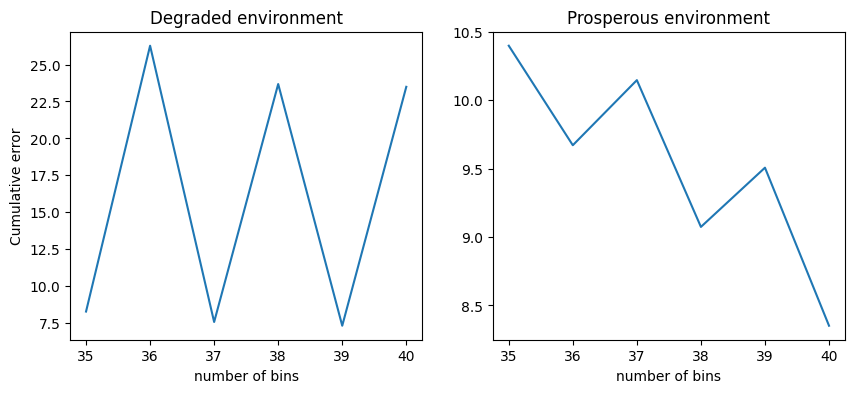

In [15]:
# Plot errors as curves

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    ax.plot(bin_nrs[-6:], errors[i, -6:])
    ax.set_xlabel("number of bins")
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")
# ax2.legend()

In [17]:
path = "data/error_calculation/"
version = "2024-04-22-v0.0"
bin_nrs = np.linspace(4, 30, 27).astype(int)
sigmas = np.linspace(0.05, 2, 40)

# Retrieve data and put it in array
errors_smooth = np.zeros((2, len(bin_nrs), len(sigmas)))
for i, nr in enumerate(bin_nrs):
    df = pd.read_csv(path+"error_df_"+str(nr)+"_bins_"+version+".csv")
    npdf = df.to_numpy()
    errors_smooth[0, i, :] = npdf[0][1:]
    errors_smooth[1, i, :] = npdf[1][1:]

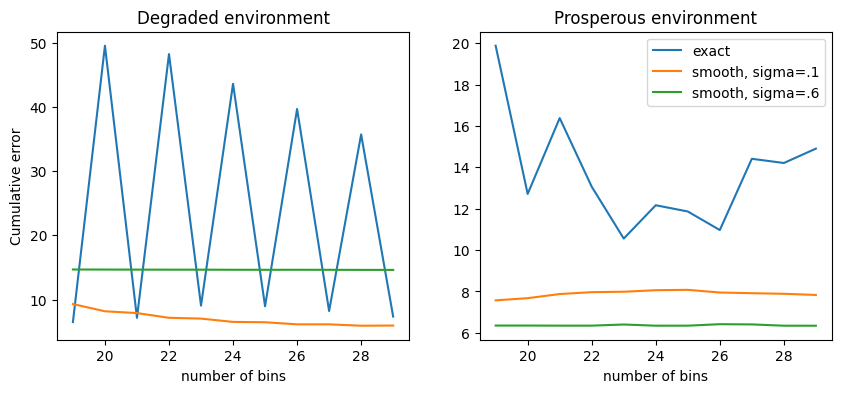

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    ax.plot(bin_nrs[-12:-1], errors[i, -22:-11], label="exact")
    ax.plot(bin_nrs[-12:-1], errors_smooth[i, -12:-1, 1], label="smooth, sigma=.1")
    ax.plot(bin_nrs[-12:-1], errors_smooth[i, -12:-1, 11], label="smooth, sigma=.6")
    ax.set_xlabel("number of bins")
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")
ax2.legend()

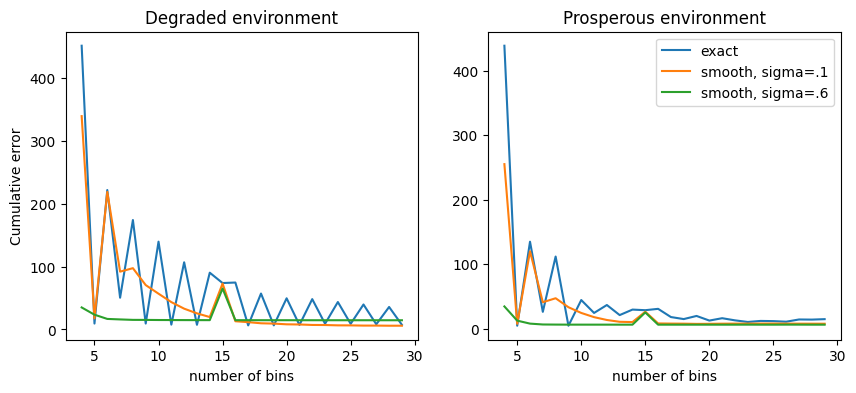

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    ax.plot(bin_nrs[:-1], errors[i, :-11], label="exact")
    ax.plot(bin_nrs[:-1], errors_smooth[i, :-1, 1], label="smooth, sigma=.1")
    ax.plot(bin_nrs[:-1], errors_smooth[i, :-1, 11], label="smooth, sigma=.6")
    ax.set_xlabel("number of bins")
ax1.set_title("Degraded environment")
ax1.set_ylabel("Cumulative error")
ax2.set_title("Prosperous environment")
ax2.legend()